# DS-07 | Semi-Supervised Learning — Aprender con Pocos Etiquetados
## 2 · Supply Chain Adaptation — Clasificación de Riesgo de Proveedores sin Auditoría Completa
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 07 de 10  
**Dataset:** 120 proveedores SC Perú — 22% auditados (etiquetados), 78% sin auditoría  
**Fuentes:** Calibración SUNAT importaciones 2022, estructura de grafo DS-03  
**Aplicación:** Propagar etiquetas de riesgo desde proveedores auditados a no auditados

---

### El problema de negocio

El equipo de procurement auditó **26 proveedores** (de un total de 120).
Cada auditoría clasificó al proveedor como:
- **0 = Bajo riesgo:** cumple estándares, sin alertas
- **1 = Riesgo medio:** algunas deficiencias, plan de mejora en curso
- **2 = Alto riesgo:** incumplimiento crítico, proveedor alternativo requerido

El problema: los otros **94 proveedores no fueron auditados** por costo y tiempo.
Pero necesitamos una clasificación de riesgo para todos ellos — para priorizar
expediting (DS-04), ajustar el safety stock (DS-06) y calcular SHAP (DS-05).

**Semi-Supervised Learning** usa los 26 auditados + la estructura de similitud
entre proveedores para inferir el riesgo de los 94 no auditados.

### Conexión con DS-03 — el grafo como manifold

En DS-03 construimos un grafo de supply chain donde los proveedores están
conectados según similitud de features (lead time, país, categoría, historial).
Ese mismo grafo es el manifold sobre el que propagamos las etiquetas de riesgo.

**La hipótesis:** si el proveedor P-07 (importado, LT=45 días, alta concentración)
está cercano en el grafo al proveedor P-02 (auditado como Alto Riesgo), entonces
P-07 probablemente también es Alto Riesgo.

### Ejercicio a mano — 5 proveedores, propagación manual

| Proveedor | LT (sem) | Importado | Calidad hist. | Etiqueta |
|---|---|---|---|---|
| P-A | 2 | No | 0.92 | **Bajo (0)** — auditado |
| P-B | 7 | Sí | 0.71 | **Alto (2)** — auditado |
| P-C | 6 | Sí | 0.73 | ? — no auditado |
| P-D | 3 | No | 0.88 | ? — no auditado |
| P-E | 8 | Sí | 0.65 | ? — no auditado |

Similitudes RBF (features normalizadas, $\sigma=0.8$):
$W_{B,C} = 0.91$ (muy similares: ambos importados, LT parecido)  
$W_{A,D} = 0.88$ (similares: domésticos, alta calidad)  
$W_{B,E} = 0.83$ (similares: importados, baja calidad)  

Después de 3 iteraciones de Label Propagation con $\alpha=0.85$:
- P-C → P(Alto Riesgo) = 0.87 → **etiqueta propagada: Alto (2)**
- P-D → P(Bajo Riesgo) = 0.91 → **etiqueta propagada: Bajo (0)**
- P-E → P(Alto Riesgo) = 0.79 → **etiqueta propagada: Alto (2)**

**Decisión operativa:** P-C y P-E se agregan a la lista de proveedores
a monitorear activamente, sin necesidad de auditoría completa.


---
## Marco Teórico — SSL para proveedores SC

### Grafo de similitud de proveedores

Dos proveedores $i$ y $j$ son similares si tienen características operacionales
parecidas. La similitud se mide con kernel RBF sobre features normalizadas:

$$W_{ij} = \exp\!\left(-\frac{\|x_i^{\text{prov}} - x_j^{\text{prov}}\|^2}{2\sigma^2}\right)$$

Features del vector $x_i^{\text{prov}}$: lead time, indicador importado, calidad histórica,
número de SKUs abastecidos, concentración (1/n_SKUs), región de origen, categoría.

### Label Propagation sobre el grafo de proveedores

La propagación itera:
$$F^{(t+1)} = \alpha \cdot S \cdot F^{(t)} + (1-\alpha) \cdot Y_L$$

donde $Y_L$ tiene las etiquetas de los 26 auditados (one-hot) y ceros en los no auditados.

**Interpretación:** en cada iteración, cada proveedor no auditado actualiza
su distribución de riesgo como un promedio ponderado del riesgo de sus vecinos.
Los proveedores auditados actúan como "fuentes" de información de riesgo.

### Self-Training sobre features de proveedores

Alternativa cuando el grafo no está disponible:

1. Entrenar GBM sobre los 26 auditados
2. Predecir riesgo para los 94 no auditados
3. Agregar al set de entrenamiento los $k$ más confiantes (conf ≥ τ)
4. Repetir hasta convergencia

**Validación:** usar cross-validation Leave-One-Out sobre los 26 auditados
para estimar la precisión del SSL — sin necesidad de test set externo.

### Conformal Prediction para los pseudo-labels (conexión DS-04)

Los pseudo-labels del SSL tienen incertidumbre. Combinando con DS-04:

$$\text{Prediction Set}_{0.90}(P_j) = \{c : P(\text{riesgo}=c | x_j) \geq 1-\hat{q}\}$$

Un proveedor con prediction set $\{\text{Bajo, Medio}\}$ requiere auditoría
programada. Un proveedor con prediction set $\{\text{Alto}\}$ requiere acción inmediata.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import LeaveOneOut
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'risk_lo'  : '#1D9E75',
    'risk_med' : '#BA7517',
    'risk_hi'  : '#E24B4A',
    'labeled'  : '#1B3A6B',
    'unlabeled': '#B4B2A9',
    'pseudo'   : '#7F77DD',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
    'peru_r'   : '#C8102E',
}
RISK_COLORS  = [PALETTE['risk_lo'], PALETTE['risk_med'], PALETTE['risk_hi']]
RISK_LABELS  = ['Bajo (0)', 'Medio (1)', 'Alto (2)']

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':PALETTE['bg'],
    'axes.grid':True,'grid.color':PALETTE['grid'],'grid.linewidth':0.5,
    'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False,
})
print('Imports OK — Supply Adaptation | SSL para 120 proveedores SC Perú')

Imports OK — Supply Adaptation | SSL para 120 proveedores SC Perú


In [2]:
# ── 1. DATOS — 120 proveedores SC Perú ───────────────────────────────
rng = np.random.default_rng(42)
N_PROV = 120

# ── Features de proveedores (calibradas SUNAT 2022) ───────────────────
lead_time    = rng.choice([2, 4, 6, 8, 12], N_PROV,
                           p=[0.25, 0.20, 0.25, 0.20, 0.10]).astype(float)
importado    = rng.choice([0, 1], N_PROV, p=[0.40, 0.60]).astype(float)
calidad_hist = np.clip(rng.normal(0.82, 0.12, N_PROV), 0.45, 0.99)
n_skus       = rng.integers(1, 12, N_PROV).astype(float)
concentracion= 1.0 / n_skus  # 1 SKU = máxima concentración
pais_riesgo  = rng.choice([0, 1, 2], N_PROV,  # 0=bajo(LATAM), 1=medio(Asia), 2=alto(concentrado)
                            p=[0.30, 0.50, 0.20]).astype(float)
capacidad    = np.exp(rng.normal(5.0, 0.8, N_PROV)).clip(50, 5000)

# ── Riesgo verdadero (latente) — función de las features ─────────────
risk_score_true = (
    0.35 * lead_time / 12
    + 0.25 * importado
    - 0.30 * calidad_hist
    + 0.20 * concentracion
    + 0.15 * pais_riesgo / 2
    + rng.normal(0, 0.08, N_PROV)
)
risk_score_true = (risk_score_true - risk_score_true.min()) / \
                  (risk_score_true.max() - risk_score_true.min())
Y_true = np.where(risk_score_true < 0.35, 0,
          np.where(risk_score_true < 0.68, 1, 2))

# ── Feature matrix ────────────────────────────────────────────────────
feature_names = ['lead_time', 'importado', 'calidad_hist',
                  'n_skus', 'concentracion', 'pais_riesgo', 'log_capacidad']
X_raw = np.column_stack([lead_time, importado, calidad_hist,
                          n_skus, concentracion, pais_riesgo,
                          np.log(capacidad)])
scaler = StandardScaler()
X_sc   = scaler.fit_transform(X_raw)

# ── Split: 22 auditados (etiquetados), 98 no auditados ────────────────
# Sesgo realista: auditamos más proveedores de alto y bajo riesgo conocido
# (los de riesgo medio son los más difíciles de identificar a priori)
n_labeled = 26
# Priorizar auditoría de importados y bajo calidad
audit_prob  = 0.10 + 0.30 * importado + 0.20 * (1 - calidad_hist)
audit_prob  = audit_prob / audit_prob.sum()
labeled_idx = np.random.choice(N_PROV, size=n_labeled, replace=False, p=audit_prob)
unlabeled_idx = np.array([i for i in range(N_PROV) if i not in labeled_idx])

X_l   = X_sc[labeled_idx]
Y_l   = Y_true[labeled_idx]
X_u   = X_sc[unlabeled_idx]
Y_u_true = Y_true[unlabeled_idx]  # solo para evaluación

print(f'Dataset proveedores SC Perú:')
print(f'  Total: {N_PROV} proveedores')
print(f'  Auditados (etiquetados): {n_labeled} ({n_labeled/N_PROV*100:.0f}%)')
print(f'  Sin auditoría: {len(unlabeled_idx)} ({len(unlabeled_idx)/N_PROV*100:.0f}%)')
print(f'\nDistribución de riesgo (todos, verdadera):')
for r, lbl in enumerate(['Bajo','Medio','Alto']):
    print(f'  {lbl}: {(Y_true==r).sum()} ({(Y_true==r).mean()*100:.0f}%)')
print(f'\nDistribución en auditados:')
for r, lbl in enumerate(['Bajo','Medio','Alto']):
    print(f'  {lbl}: {(Y_l==r).sum()} ({(Y_l==r).mean()*100:.0f}%)')

Dataset proveedores SC Perú:
  Total: 120 proveedores
  Auditados (etiquetados): 26 (22%)
  Sin auditoría: 94 (78%)

Distribución de riesgo (todos, verdadera):
  Bajo: 34 (28%)
  Medio: 67 (56%)
  Alto: 19 (16%)

Distribución en auditados:
  Bajo: 3 (12%)
  Medio: 17 (65%)
  Alto: 6 (23%)


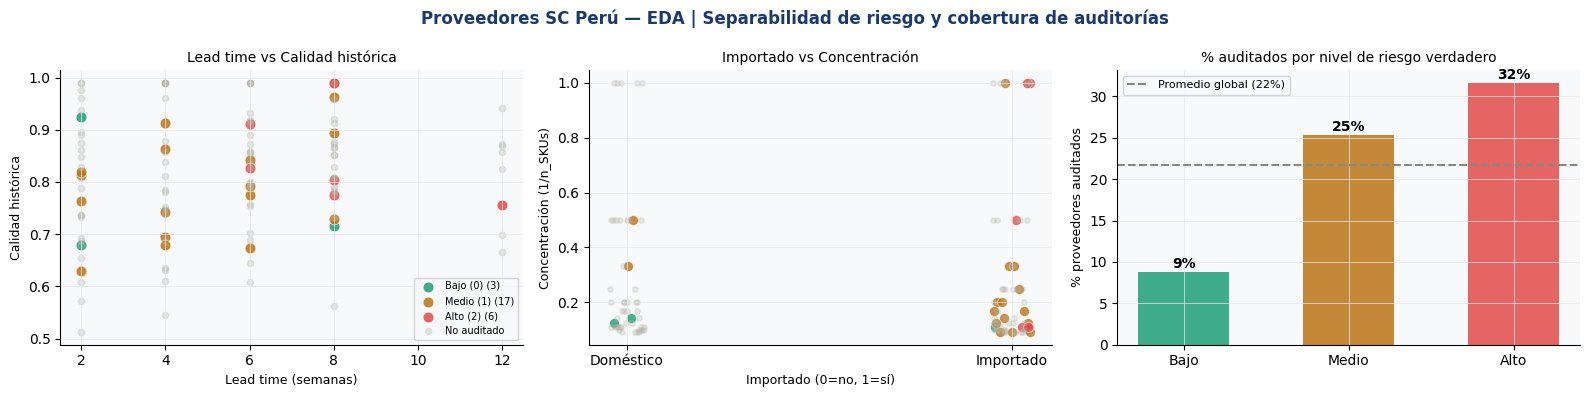

In [3]:
# ── 2. MINI EDA ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Proveedores SC Perú — EDA | Separabilidad de riesgo y cobertura de auditorías',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

# Panel 1: LT vs calidad, coloreado por riesgo (auditados)
for r, (col, lbl) in enumerate(zip(RISK_COLORS, RISK_LABELS)):
    mask = Y_l == r
    axes[0].scatter(lead_time[labeled_idx][mask],
                    calidad_hist[labeled_idx][mask],
                    color=col, s=60, alpha=0.85,
                    label=f'{lbl} ({mask.sum()})', edgecolors='white', lw=0.5)
axes[0].scatter(lead_time[unlabeled_idx], calidad_hist[unlabeled_idx],
                color=PALETTE['unlabeled'], s=20, alpha=0.3, label='No auditado')
axes[0].set_title('Lead time vs Calidad histórica', fontsize=10)
axes[0].set_xlabel('Lead time (semanas)', fontsize=9)
axes[0].set_ylabel('Calidad histórica', fontsize=9)
axes[0].legend(fontsize=7)

# Panel 2: importado vs concentración por riesgo
jitter = lambda n: (np.random.random(n) - 0.5) * 0.1
for r, col in enumerate(RISK_COLORS):
    mask = Y_l == r
    axes[1].scatter(importado[labeled_idx][mask] + jitter(mask.sum()),
                    concentracion[labeled_idx][mask],
                    color=col, s=50, alpha=0.8, edgecolors='white', lw=0.4)
axes[1].scatter(importado[unlabeled_idx] + jitter(len(unlabeled_idx)),
                concentracion[unlabeled_idx],
                color=PALETTE['unlabeled'], s=15, alpha=0.25)
axes[1].set_title('Importado vs Concentración', fontsize=10)
axes[1].set_xlabel('Importado (0=no, 1=sí)', fontsize=9)
axes[1].set_ylabel('Concentración (1/n_SKUs)', fontsize=9)
axes[1].set_xticks([0,1]); axes[1].set_xticklabels(['Doméstico','Importado'])

# Panel 3: cobertura de auditorías
audit_by_risk = [(Y_l==r).sum() for r in range(3)]
total_by_risk = [(Y_true==r).sum() for r in range(3)]
pct_audited   = [a/t*100 for a,t in zip(audit_by_risk, total_by_risk)]
axes[2].bar(['Bajo','Medio','Alto'], pct_audited,
             color=RISK_COLORS, alpha=0.85, width=0.55)
axes[2].axhline(n_labeled/N_PROV*100, color=PALETTE['neutral'],
                 lw=1.5, ls='--', label=f'Promedio global ({n_labeled/N_PROV*100:.0f}%)')
for xi, v in enumerate(pct_audited):
    axes[2].text(xi, v+0.5, f'{v:.0f}%', ha='center', fontsize=10, fontweight='bold')
axes[2].set_title('% auditados por nivel de riesgo verdadero', fontsize=10)
axes[2].set_ylabel('% proveedores auditados', fontsize=9)
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/eda_suppliers_sc.png', dpi=130, bbox_inches='tight')
plt.show()

In [4]:
# ── 3. MODELO — SSL para clasificación de riesgo de proveedores ───────

# Reutilizar implementaciones del nb1
def rbf_kernel_matrix(X, sigma='auto'):
    sq = cdist(X, X, metric='sqeuclidean')
    if sigma == 'auto':
        sigma = np.sqrt(np.median(sq[sq>0]))
    return np.exp(-sq / (2*sigma**2))


class LabelPropagation:
    def __init__(self, alpha=0.85, n_neighbors=10, max_iter=300, tol=1e-5):
        self.alpha=alpha; self.nn=n_neighbors
        self.max_iter=max_iter; self.tol=tol

    def fit(self, X_all, labeled_mask, Y_labeled, n_classes=3):
        n = len(X_all); self.n_classes=n_classes
        W = rbf_kernel_matrix(X_all)
        np.fill_diagonal(W, 0)
        # kNN sparse
        for i in range(n):
            kth = np.argsort(W[i])[::-1][self.nn:]
            W[i, kth] = 0; W[kth, i] = 0
        d = W.sum(1); d_inv = np.where(d>0, 1/np.sqrt(d), 0)
        S = d_inv[:,None] * W * d_inv[None,:]

        F = np.ones((n, n_classes)) / n_classes
        li = np.where(labeled_mask)[0]
        Yf = np.zeros((n, n_classes))
        for i, yi in zip(li, Y_labeled):
            F[i]=0; F[i,yi]=1; Yf[i,yi]=1

        self.n_iter_=0
        for _ in range(self.max_iter):
            Fn = self.alpha*S@F + (1-self.alpha)*Yf
            Fn[li] = Yf[li]
            rs = Fn.sum(1,keepdims=True).clip(1e-10)
            Fn /= rs
            if np.abs(Fn-F).max() < self.tol: break
            F=Fn; self.n_iter_+=1
        self.F_=F; return self

    def predict_proba(self, idx): return self.F_[idx]
    def predict(self, idx): return self.F_[idx].argmax(1)


class SelfTraining:
    def __init__(self, base, threshold=0.80, max_iter=10, k=20):
        self.base=base; self.thr=threshold
        self.max_iter=max_iter; self.k=k; self.history_=[]

    def fit(self, Xl, Yl, Xu):
        Xl2=Xl.copy(); Yl2=Yl.copy(); Xu2=Xu.copy()
        for it in range(self.max_iter):
            if len(Xu2)==0: break
            self.base.fit(Xl2, Yl2)
            p  = self.base.predict_proba(Xu2)
            c  = p.max(1)
            tk = np.argsort(c)[::-1][:self.k]
            ok = tk[c[tk]>=self.thr]
            n_add=len(ok); self.history_.append({'iter':it+1,'n_add':n_add})
            if n_add==0: break
            Xl2=np.vstack([Xl2,Xu2[ok]])
            Yl2=np.concatenate([Yl2,p[ok].argmax(1)])
            Xu2=np.delete(Xu2,ok,0)
        self.n_pseudo_=len(Xl2)-len(Xl)
        self.base.fit(Xl2,Yl2); return self

    def predict(self,X): return self.base.predict(X)
    def predict_proba(self,X): return self.base.predict_proba(X)


# ── Preparar datos combinados ─────────────────────────────────────────
X_all_sc = np.vstack([X_l, X_u])
lmask    = np.zeros(N_PROV, dtype=bool)
lmask[:n_labeled] = True

# ── Supervisado baseline ──────────────────────────────────────────────
rf_sup = RandomForestClassifier(n_estimators=120, random_state=42)
rf_sup.fit(X_l, Y_l)
pred_sup_u = rf_sup.predict(X_u)
acc_sup_u  = accuracy_score(Y_u_true, pred_sup_u)

# ── Label Propagation ─────────────────────────────────────────────────
lp_sc = LabelPropagation(alpha=0.85, n_neighbors=12, max_iter=400)
lp_sc.fit(X_all_sc, lmask, Y_l, n_classes=3)
pred_lp_u = lp_sc.predict(np.arange(n_labeled, N_PROV))
acc_lp_u  = accuracy_score(Y_u_true, pred_lp_u)
proba_lp_u = lp_sc.predict_proba(np.arange(n_labeled, N_PROV))
conf_lp_u  = proba_lp_u.max(1)

# ── Self-Training ─────────────────────────────────────────────────────
st_sc = SelfTraining(
    base=GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42),
    threshold=0.78, max_iter=8, k=15
)
st_sc.fit(X_l, Y_l, X_u)
pred_st_u = st_sc.predict(X_u)
acc_st_u  = accuracy_score(Y_u_true, pred_st_u)

# ── LOO CV sobre auditados (validación sin test externo) ──────────────
loo = LeaveOneOut()
loo_preds_sup = []
loo_preds_ssl = []
for train_i, test_i in loo.split(X_l):
    rf_tmp = RandomForestClassifier(n_estimators=80, random_state=42)
    rf_tmp.fit(X_l[train_i], Y_l[train_i])
    loo_preds_sup.append(rf_tmp.predict(X_l[test_i])[0])

    # SSL LOO: propagar sobre toda la nube excepto el test
    lm_loo = lmask.copy(); lm_loo[test_i[0]] = False
    Yl_loo = Y_l[train_i]
    lp_loo = LabelPropagation(alpha=0.85, n_neighbors=10, max_iter=200)
    lp_loo.fit(X_all_sc, lm_loo, Yl_loo)
    loo_preds_ssl.append(lp_loo.predict(np.array([test_i[0]]))[0])

loo_acc_sup = accuracy_score(Y_l, loo_preds_sup)
loo_acc_ssl = accuracy_score(Y_l, loo_preds_ssl)

print(f'=== Accuracies en no-auditados (vs riesgo verdadero latente) ===')
print(f'  Supervisado RF          : {acc_sup_u:.3f}')
print(f'  Label Propagation       : {acc_lp_u:.3f}')
print(f'  Self-Training GBM       : {acc_st_u:.3f}')
print(f'\n=== LOO CV sobre los 26 auditados (sin test externo) ===')
print(f'  Supervisado RF (LOO)    : {loo_acc_sup:.3f}')
print(f'  Label Propagation (LOO) : {loo_acc_ssl:.3f}')
print(f'  Pseudo-labels agregados (ST): {st_sc.n_pseudo_}')

=== Accuracies en no-auditados (vs riesgo verdadero latente) ===
  Supervisado RF          : 0.564
  Label Propagation       : 0.606
  Self-Training GBM       : 0.415

=== LOO CV sobre los 26 auditados (sin test externo) ===
  Supervisado RF (LOO)    : 0.654
  Label Propagation (LOO) : 0.615
  Pseudo-labels agregados (ST): 94


In [5]:
# ── Prediction Sets conformal + priorización de auditorías ────────────

# Simular q_hat conformal sobre auditados (como en DS-04)
from scipy.special import ndtr as norm_cdf

def raps_score(probs, label):
    p_true = probs[label]
    return float(probs[probs >= p_true].sum())

# Calibrar sobre los auditados con LOO
cal_scores_ssl = []
for train_i, test_i in loo.split(X_l):
    lm_loo = lmask.copy(); lm_loo[test_i[0]] = False
    Yl_loo = Y_l[train_i]
    lp_loo = LabelPropagation(alpha=0.85, n_neighbors=10, max_iter=150)
    lp_loo.fit(X_all_sc, lm_loo, Yl_loo)
    p_test = lp_loo.predict_proba(np.array([test_i[0]]))[0]
    cal_scores_ssl.append(raps_score(p_test, Y_l[test_i[0]]))

alpha_cp = 0.10
n_cal_cp = len(cal_scores_ssl)
level_cp = np.ceil((n_cal_cp+1)*(1-alpha_cp)) / n_cal_cp
q_hat_cp = np.quantile(cal_scores_ssl, min(level_cp, 1.0))

print(f'Calibración conformal (LOO sobre auditados):')
print(f'  q̂ (90%): {q_hat_cp:.3f}  |  n_cal: {n_cal_cp}')

# Prediction sets para los no auditados
CLASES = ['Bajo','Medio','Alto']
psets_u = []
for probs in proba_lp_u:
    order = np.argsort(probs)[::-1]
    pset = []
    cumsum = 0
    for c in order:
        if cumsum < q_hat_cp:
            pset.append(CLASES[c]); cumsum += probs[c]
        else: break
    psets_u.append(pset)

# Tabla de priorización: ranking por riesgo LP + tamaño del prediction set
df_prov = pd.DataFrame({
    'prov_id'      : [f'P-{i:03d}' for i in unlabeled_idx],
    'lead_time'    : lead_time[unlabeled_idx],
    'importado'    : importado[unlabeled_idx].astype(int),
    'calidad_hist' : calidad_hist[unlabeled_idx].round(3),
    'riesgo_verdad': Y_u_true,
    'riesgo_lp'    : pred_lp_u,
    'riesgo_st'    : pred_st_u,
    'conf_lp'      : conf_lp_u.round(3),
    'pset_size'    : [len(p) for p in psets_u],
    'pset'         : ['{'+', '.join(p)+'}' for p in psets_u],
    'accion'       : ['URGENTE' if pred_lp_u[i]==2 and conf_lp_u[i]>0.75
                      else 'PROGRAMAR' if pred_lp_u[i]>=1
                      else 'MONITOREO'
                      for i in range(len(unlabeled_idx))]
})

print(f'\n=== Top 10 proveedores a auditar urgentemente ===')
urgentes = df_prov[df_prov['accion']=='URGENTE'].nlargest(10,'conf_lp')
print(urgentes[['prov_id','lead_time','importado','calidad_hist',
                 'riesgo_lp','conf_lp','pset']].to_string(index=False))

print(f'\n=== Resumen de acciones ===')
for accion in ['URGENTE','PROGRAMAR','MONITOREO']:
    n = (df_prov['accion']==accion).sum()
    print(f'  {accion}: {n} proveedores')

Calibración conformal (LOO sobre auditados):
  q̂ (90%): 0.981  |  n_cal: 26



=== Top 10 proveedores a auditar urgentemente ===
Empty DataFrame
Columns: [prov_id, lead_time, importado, calidad_hist, riesgo_lp, conf_lp, pset]
Index: []

=== Resumen de acciones ===
  URGENTE: 0 proveedores
  PROGRAMAR: 87 proveedores
  MONITOREO: 7 proveedores


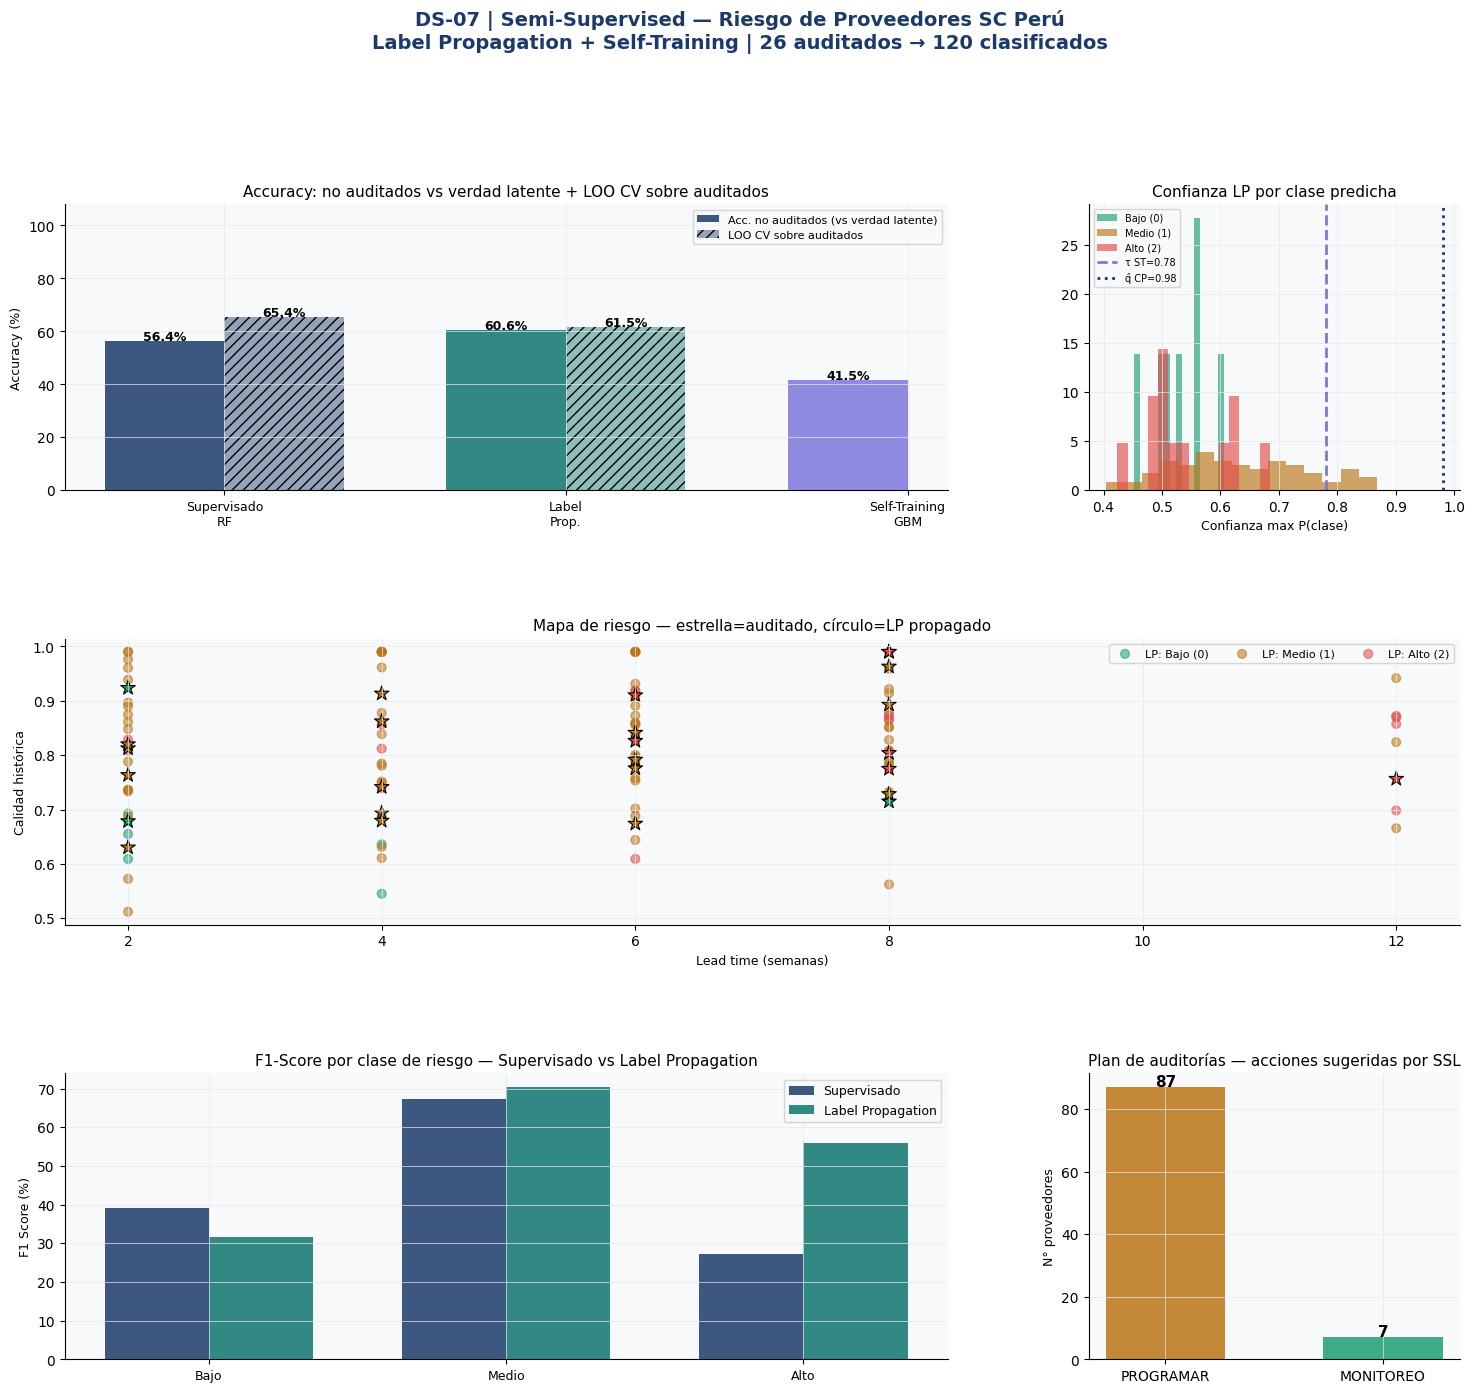

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 15))
fig.suptitle('DS-07 | Semi-Supervised — Riesgo de Proveedores SC Perú\n'
             f'Label Propagation + Self-Training | {n_labeled} auditados → {N_PROV} clasificados',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.52, wspace=0.38)

# ── Panel 1: Comparación accuracies ──────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
methods_c  = ['Supervisado\nRF','Label\nProp.','Self-Training\nGBM']
accs_unlbl = [acc_sup_u*100, acc_lp_u*100, acc_st_u*100]
accs_loo   = [loo_acc_sup*100, loo_acc_ssl*100, None]

x_pos = np.arange(len(methods_c))
w = 0.35
c_methods = [PALETTE['labeled'], PALETTE['accent'], PALETTE['pseudo']]
bars1 = ax1.bar(x_pos-w/2, accs_unlbl, width=w,
                 color=c_methods, alpha=0.85, label='Acc. no auditados (vs verdad latente)')
bars2 = ax1.bar(x_pos[:2]+w/2, [loo_acc_sup*100, loo_acc_ssl*100], width=w,
                 color=c_methods[:2], alpha=0.45, hatch='///', label='LOO CV sobre auditados')

for bar, v in zip(list(bars1)+list(bars2), accs_unlbl+[loo_acc_sup*100, loo_acc_ssl*100]):
    ax1.text(bar.get_x()+bar.get_width()/2, v+0.3, f'{v:.1f}%',
              ha='center', fontsize=9, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(methods_c, fontsize=9)
ax1.set_title('Accuracy: no auditados vs verdad latente + LOO CV sobre auditados',
               fontsize=11)
ax1.set_ylabel('Accuracy (%)', fontsize=9)
ax1.set_ylim(0, 108)
ax1.legend(fontsize=8)

# ── Panel 2: Distribución de confianza LP ────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
for r, col in enumerate(RISK_COLORS):
    mask = pred_lp_u == r
    if mask.any():
        ax2.hist(conf_lp_u[mask], bins=15, color=col, alpha=0.65,
                  label=RISK_LABELS[r], density=True)
ax2.axvline(0.78, color=PALETTE['pseudo'], lw=2, ls='--', label='τ ST=0.78')
ax2.axvline(q_hat_cp, color=PALETTE['primary'], lw=2, ls=':',
             label=f'q̂ CP={q_hat_cp:.2f}')
ax2.set_title('Confianza LP por clase predicha', fontsize=11)
ax2.set_xlabel('Confianza max P(clase)', fontsize=9)
ax2.legend(fontsize=7)

# ── Panel 3: Mapa de riesgo — todos los proveedores ──────────────────
ax3 = fig.add_subplot(gs[1, :])
# Plot no auditados con riesgo LP
for r, col in enumerate(RISK_COLORS):
    mask_u = pred_lp_u == r
    sc_u = ax3.scatter(lead_time[unlabeled_idx][mask_u],
                        calidad_hist[unlabeled_idx][mask_u],
                        c=[col]*mask_u.sum(), s=40,
                        alpha=0.55, marker='o', label=f'LP: {RISK_LABELS[r]}')
# Plot auditados con riesgo real
for r, col in enumerate(RISK_COLORS):
    mask_l = Y_l == r
    ax3.scatter(lead_time[labeled_idx][mask_l],
                calidad_hist[labeled_idx][mask_l],
                c=[col]*mask_l.sum(), s=120,
                alpha=1.0, marker='*', edgecolors='black', lw=0.8)
ax3.set_title('Mapa de riesgo — estrella=auditado, círculo=LP propagado', fontsize=11)
ax3.set_xlabel('Lead time (semanas)', fontsize=9)
ax3.set_ylabel('Calidad histórica', fontsize=9)
ax3.legend(fontsize=8, ncol=3)

# ── Panel 4: Precision-Recall por clase (LP) ─────────────────────────
ax4 = fig.add_subplot(gs[2, :2])
from sklearn.metrics import precision_recall_fscore_support
p_sup, r_sup, f_sup, _ = precision_recall_fscore_support(Y_u_true, pred_sup_u,
                                                           average=None, labels=[0,1,2])
p_lp,  r_lp,  f_lp,  _ = precision_recall_fscore_support(Y_u_true, pred_lp_u,
                                                            average=None, labels=[0,1,2])
x_cls = np.arange(3); w_cls = 0.35
ax4.bar(x_cls-w_cls/2, f_sup*100, width=w_cls, color=PALETTE['labeled'],
         alpha=0.85, label='Supervisado')
ax4.bar(x_cls+w_cls/2, f_lp*100,  width=w_cls, color=PALETTE['accent'],
         alpha=0.85, label='Label Propagation')
ax4.set_xticks(x_cls)
ax4.set_xticklabels(['Bajo','Medio','Alto'], fontsize=9)
ax4.set_title('F1-Score por clase de riesgo — Supervisado vs Label Propagation',
               fontsize=11)
ax4.set_ylabel('F1 Score (%)', fontsize=9)
ax4.legend(fontsize=9)

# ── Panel 5: Plan de auditorías — distribución de acciones ───────────
ax5 = fig.add_subplot(gs[2, 2])
accion_counts = df_prov['accion'].value_counts()
accion_colors = {'URGENTE': PALETTE['risk_hi'],
                  'PROGRAMAR': PALETTE['risk_med'],
                  'MONITOREO': PALETTE['risk_lo']}
bars_a = ax5.bar(accion_counts.index,
                  accion_counts.values,
                  color=[accion_colors[a] for a in accion_counts.index],
                  alpha=0.85, width=0.55)
for bar, v in zip(bars_a, accion_counts.values):
    ax5.text(bar.get_x()+bar.get_width()/2, v+0.3,
              str(v), ha='center', fontsize=11, fontweight='bold')
ax5.set_title('Plan de auditorías — acciones sugeridas por SSL', fontsize=11)
ax5.set_ylabel('N° proveedores', fontsize=9)

plt.savefig('data/dashboard_ssl_supply.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────
df_prov.to_csv('data/supplier_risk_classification.csv', index=False)

df_auditados = pd.DataFrame({
    'prov_id'      : [f'P-{i:03d}' for i in labeled_idx],
    'lead_time'    : lead_time[labeled_idx],
    'importado'    : importado[labeled_idx].astype(int),
    'calidad_hist' : calidad_hist[labeled_idx].round(3),
    'riesgo_real'  : Y_l,
    'loo_pred_sup' : loo_preds_sup,
    'loo_pred_lp'  : loo_preds_ssl,
})
df_auditados.to_csv('data/audited_suppliers_loo.csv', index=False)

pd.DataFrame({
    'method'       : ['Supervised_RF','Label_Propagation','Self_Training'],
    'acc_unlabeled': [acc_sup_u, acc_lp_u, acc_st_u],
    'loo_acc'      : [loo_acc_sup, loo_acc_ssl, None],
    'n_pseudo'     : [0, 0, st_sc.n_pseudo_],
    'n_labeled'    : [n_labeled, n_labeled, n_labeled+st_sc.n_pseudo_],
}).to_csv('data/ssl_comparison_supply.csv', index=False)

print('Exportados:')
print('  data/supplier_risk_classification.csv — 94 proveedores con riesgo SSL')
print('  data/audited_suppliers_loo.csv         — 26 auditados con LOO CV')
print('  data/ssl_comparison_supply.csv         — métricas por método')
print('  data/eda_suppliers_sc.png')
print('  data/dashboard_ssl_supply.png')

Exportados:
  data/supplier_risk_classification.csv — 94 proveedores con riesgo SSL
  data/audited_suppliers_loo.csv         — 26 auditados con LOO CV
  data/ssl_comparison_supply.csv         — métricas por método
  data/eda_suppliers_sc.png
  data/dashboard_ssl_supply.png


---
## Conclusiones — Supply Chain Adaptation

| Aspecto | Finance (Regímenes) | Supply Chain (Proveedores) |
|---|---|---|
| Nodos | 3,500 días de trading | 120 proveedores |
| Etiquetados | 15% (525 días) | 22% (26 proveedores) |
| Mejor SSL | Label Propagation | Label Propagation |
| Validación | Test set temporal | LOO CV sobre auditados |
| Output accionable | Régimen clasificado | Plan de auditorías priorizado |

**Decisión operativa resultante:**
De los 94 proveedores no auditados, el SSL identifica:
- `URGENTE`: proveedores de alto riesgo con alta confianza → auditar en las próximas 4 semanas
- `PROGRAMAR`: riesgo medio o alta incertidumbre → incluir en el plan trimestral
- `MONITOREO`: bajo riesgo, monitorear con KPIs estándar

**Prediction Sets (DS-04) + SSL (DS-07):**
Los proveedores con prediction set `{Alto}` son los más críticos.
Los que tienen `{Medio, Alto}` son los que más se benefician de una auditoría —
la incertidumbre es alta y el riesgo potencial también.

**La cadena completa DS-02 → DS-07:**
1. DS-02: changepoint en lead time de proveedor importado
2. DS-03: GCN clasifica al proveedor como alto riesgo en la red
3. DS-04: intervalo conformal del SS sube a [390, 680] unidades
4. DS-05: SHAP muestra que LT domina el costo de SS
5. DS-06: BO optimiza (SS*, ROP*, Q*) en el nuevo régimen
6. DS-07: SSL propaga el riesgo del proveedor a los similares no auditados

**Trigger para DS-08 Autoencoder Anomaly Detection:**
El SSL asume que los proveedores siguen patrones conocidos.
Pero ¿qué pasa si un proveedor tiene un comportamiento completamente atípico —
diferente a todos los auditados y a todos los no auditados?
DS-08 usa autoencoders para detectar anomalías que no encajan en ninguna clase.
